In [178]:
import pandas as pd

movies = pd.read_csv('data/movies.csv')

print("Shape:", movies.shape)
print("\nColumn types and non-null counts:")
movies.info()

Shape: (3201, 16)

Column types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   str    
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14

What one row is and which columns you will use?

The dataset has 3,201 rows and 16 columns. Each row represents one film.
I will focus on Title, Release Date, Production Budget, Worldwide Gross, Major Genre, Rotten Tomatoes Rating and IMDB Rating

The first problem is Release Date format - it is a string, but should be a datetime. Also check min and max dates

In [179]:
# Convert Release Date to datetime and check min/max dates
movies['Release Date'] = pd.to_datetime(movies['Release Date'])

print("Min date:", movies['Release Date'].min())
print("Max date:", movies['Release Date'].max())

Min date: 1928-12-31 00:00:00
Max date: 2046-12-31 00:00:00


The maximum date is 2046-12-31 is impossible. Checking the repository on GitHub shows the data was not updated after 2020, so any date after 2020 must be an error.

In [180]:
# Check which films have dates in the future (after 2020 for our data)
future_dates = movies['Release Date'].dt.year > 2020
print("Films with future dates:", future_dates.sum())

movies.loc[future_dates, ['Title', 'Release Date']]

Films with future dates: 18


,Title,Release Date
9,Duel in the Sun,2046-12-31
16,Wilson,2044-08-01
33,42nd Street,2033-03-09
85,Ben-Hur,2025-12-30
90,The Best Years of Our Lives,2046-11-21
102,The Big Parade,2025-01-01
174,"Charge of the Light Brigade, The",2036-10-20
221,Cat People,2042-11-16
337,Fantasia,2040-11-13
382,A Guy Named Joe,2043-12-24


18 rows have release dates between 2025 and 2046, which is impossible since the dataset ends in 2020. Instead of guessing the exact dates, I replace them with missing values (NaT) so they do not distort any time-based checks.

In [181]:
movies.loc[future_dates, 'Release Date'] = pd.NaT

print("Min date after fix:", movies['Release Date'].min())
print("Max date after fix:", movies['Release Date'].max())

Min date after fix: 1928-12-31 00:00:00
Max date after fix: 2020-09-17 00:00:00


Check Production Budget

In [182]:
# Check summary statistics, missing values, and zeros in Production Budget
print(movies['Production Budget'].describe())
print("\nMissing values:", movies['Production Budget'].isna().sum())
print("Zero values:", (movies['Production Budget'] == 0).sum())
print("Negative values:", (movies['Production Budget'] < 0).sum())

count    3.200000e+03
mean     3.106917e+07
std      3.558591e+07
min      2.180000e+02
25%      6.575000e+06
50%      2.000000e+07
75%      4.200000e+07
max      3.000000e+08
Name: Production Budget, dtype: float64

Missing values: 1
Zero values: 0
Negative values: 0


In [183]:
# Check the film with the minimum Production Budget
min_budget = movies['Production Budget'].min()
movies.loc[movies['Production Budget'] == min_budget, ['Title', 'Release Date', 'Production Budget', 'Worldwide Gross']]

# Check the film with the maximum Production Budget
max_budget = movies['Production Budget'].max()
movies.loc[movies['Production Budget'] == max_budget, ['Title', 'Release Date', 'Production Budget', 'Worldwide Gross']]

,Title,Release Date,Production Budget,Worldwide Gross
2508,Pirates of the Caribbean: At World's End,2007-05-25,300000000.0,960996492.0


Production Budget has 3200 valid values (1 missing) and no zeros or negative numbers.
The minimum budget ($218 for Tarnation) is a real micro-budget documentary, not an error.
The maximum budget ($300,000,000 for Pirates of the Caribbean: At World's End) is a real budget also.

Therefore, Production Budget needs no cleaning.

Check Worldwide Gross

In [184]:
# Find films with 0 in Worldwide Gross
print("Zero Worldwide Gross:", (movies['Worldwide Gross'] == 0).sum())

movies.loc[movies['Worldwide Gross'] == 0, ['Title', 'Release Date', 'Production Budget', 'Worldwide Gross']].head(10)

Zero Worldwide Gross: 47


,Title,Release Date,Production Budget,Worldwide Gross
19,12 Angry Men,1957-04-13,340000.0,0.0
21,1776,1972-11-09,4000000.0,0.0
48,Alice in Wonderland,1951-07-28,3000000.0,0.0
68,Barbarella,1968-10-10,9000000.0,0.0
94,Big Things,2009-12-31,50000.0,0.0
123,The Blood of My Brother: A Story of Death in Iraq,2006-06-30,120000.0,0.0
147,Batman - The Movie,2001-08-21,1377800.0,0.0
162,Crop Circles: Quest for Truth,2002-08-23,600000.0,0.0
174,"Charge of the Light Brigade, The",NaT,1200000.0,0.0
211,Crying With Laughter,2009-12-31,820000.0,0.0


47 films have 0 in Worldwide Gross, even though they have real production budgets. Here 0 means missing data and leaving 0 would pull down average earnings.

In [185]:
# Replace 0 with missing values
movies['Worldwide Gross'] = movies['Worldwide Gross'].replace(0, pd.NA)

print("Zero Worldwide Gross after fix:", (movies['Worldwide Gross'] == 0).sum())

Zero Worldwide Gross after fix: 0


Check Major Genre, Rotten Tomatoes Rating, and IMDB Rating

In [186]:
print("Major Genre categories:")
print(movies['Major Genre'].value_counts(dropna=False))

print("\nRotten Tomatoes Rating:")
print(movies['Rotten Tomatoes Rating'].describe())

print("\nIMDB Rating:")
print(movies['IMDB Rating'].describe())

Major Genre categories:
Major Genre
Drama                  789
Comedy                 675
Action                 420
NaN                    275
Adventure              274
Thriller/Suspense      239
Horror                 219
Romantic Comedy        137
Musical                 53
Documentary             43
Western                 36
Black Comedy            36
Concert/Performance      5
Name: count, dtype: int64

Rotten Tomatoes Rating:
count    2321.000000
mean       54.336924
std        28.076593
min         1.000000
25%        30.000000
50%        55.000000
75%        80.000000
max       100.000000
Name: Rotten Tomatoes Rating, dtype: float64

IMDB Rating:
count    2988.000000
mean        6.283467
std         1.252290
min         1.400000
25%         5.600000
50%         6.400000
75%         7.200000
max         9.200000
Name: IMDB Rating, dtype: float64


No need to fix data in Major Genre, Rotten Tomatoes Rating, and IMDB Rating on this step

### Handle the missing values in other columns also

In [187]:
movies.isna().sum()

Title                        1
US Gross                     7
Worldwide Gross             54
US DVD Sales              2637
Production Budget            1
Release Date                18
MPAA Rating                605
Running Time min          1992
Distributor                232
Source                     365
Major Genre                275
Creative Type              446
Director                  1331
Rotten Tomatoes Rating     880
IMDB Rating                213
IMDB Votes                 213
dtype: int64

In [188]:
(movies.isna().mean() * 100).round(1)

Title                      0.0
US Gross                   0.2
Worldwide Gross            1.7
US DVD Sales              82.4
Production Budget          0.0
Release Date               0.6
MPAA Rating               18.9
Running Time min          62.2
Distributor                7.2
Source                    11.4
Major Genre                8.6
Creative Type             13.9
Director                  41.6
Rotten Tomatoes Rating    27.5
IMDB Rating                6.7
IMDB Votes                 6.7
dtype: float64

For 'Rotten Tomatoes Rating' (27.5% missing) and 'Major Genre' (8.6% missing) I decided to keep the missing values as 'NaN' rather than dropping rows or filling them in. In 'Rotten Tomatoes Rating' missing values mean that older, foreign or lesser-known films did not receive enough reviews. In 'Major Genre' missing entries reflects incomplete metadata in the original database rather than a special category. Filling these gaps with average ratings or guessed genre would distort our statistics, and dropping rows would unnecessarily remove hundreds of films from other parts of analysis.

Similarly, for 'US DVD Sales' (82.4% missing) I keep the column untouched without dropping any rows. Here missing values mean the film was released before DVD existed or had no reported DVD sales. Leaving all missing values as 'NaN' ensures that each calculation only excludes missing entries for the specific column being analyzed.

### Merge both tables

In [189]:
genre_groups = pd.read_csv('data/genre_groups.csv')
genre_groups

,Major Genre,Genre group
0,Drama,Drama
1,Comedy,Comedy & music
2,Romantic Comedy,Comedy & music
3,Black Comedy,Comedy & music
4,Musical,Comedy & music
5,Action,Action & adventure
6,Adventure,Action & adventure
7,Western,Action & adventure
8,Thriller/Suspense,Thriller & horror
9,Horror,Thriller & horror


In [190]:
print("Rows before merge:", len(movies))

movies = movies.merge(genre_groups, on='Major Genre', how='left')

print("Rows after merge:", len(movies))
movies[['Title', 'Major Genre', 'Genre group']].head(10)

Rows before merge: 3201
Rows after merge: 3201


,Title,Major Genre,Genre group
0,The Land Girls,NaN,NaN
1,"First Love, Last Rites",Drama,Drama
2,I Married a Strange Person,Comedy,Comedy & music
3,Let's Talk About Sex,Comedy,Comedy & music
4,Slam,Drama,Drama
5,Mississippi Mermaid,NaN,NaN
6,Following,NaN,NaN
7,Foolish,Comedy,Comedy & music
8,Pirates,NaN,NaN
9,Duel in the Sun,NaN,NaN


In [191]:
movies['Genre group'].value_counts(dropna=False)

Genre group
Comedy & music        901
Drama                 789
Action & adventure    730
Thriller & horror     458
NaN                   275
Non-fiction            48
Name: count, dtype: int64

### 5. Create at least two new columns

In [192]:
# 1. Profit and return ratio
movies['Profit'] = movies['Worldwide Gross'] - movies['Production Budget']
movies['Return ratio'] = movies['Worldwide Gross'] / movies['Production Budget']

# Difference between critic and audience scores
movies['Rating diff'] = movies['Rotten Tomatoes Rating'] - (movies['IMDB Rating'] * 10)

# 3. Budget category (Low, Medium, High) to group films by budget size
movies['Budget group'] = pd.cut(
    movies['Production Budget'],
    bins=[0, 15000000, 50000000, float('inf')],
    labels=['Low', 'Medium', 'High']
)

movies[['Title', 'Budget group', 'Profit', 'Return ratio', 'Rating diff']].head(10)

,Title,Budget group,Profit,Return ratio,Rating diff
0,The Land Girls,Low,-7853917.0,0.01826,NaN
1,"First Love, Last Rites",Low,-289124.0,0.036253,NaN
2,I Married a Strange Person,Low,-46866.0,0.812536,NaN
3,Let's Talk About Sex,Low,73615.0,1.245383,NaN
4,Slam,Low,87521.0,1.087521,28.0
5,Mississippi Mermaid,Low,1024551.0,1.640344,NaN
6,Following,Low,38705.0,7.450833,NaN
7,Foolish,Low,4426908.0,3.766818,NaN
8,Pirates,Medium,-33658175.0,0.158546,-33.0
9,Duel in the Sun,Low,14400000.0,3.4,16.0


### Group and compare

#### Question 1: Do films with a big budget earn more worldwide, and are they more profitable?

In [193]:
movies.groupby('Budget group')[['Worldwide Gross', 'Profit', 'Return ratio']].agg(['count', 'mean', 'median'])

Worldwide Gross                                Profit  \
                       count              mean       median  count   
Budget group                                                         
Low                     1375   28301078.693818   10037390.0   1375   
Medium                  1155   74294721.728139   43440721.0   1155   
High                     616  239931885.987013  164924114.0    616   

                                           Return ratio                       
                          mean      median        count       mean    median  
Budget group                                                                  
Low            21861378.119273   4231215.0         1375  23.540939  2.143188  
Medium          44183552.89697  14159144.0         1155   2.564375  1.491878  
High          150549675.535714  91041185.0          616   2.552661  2.029505

In [194]:
cols = ['Production Budget', 'Worldwide Gross', 'Profit', 'Return ratio']
movies[cols].astype('Float64').corr()

,Production Budget,Worldwide Gross,Profit,Return ratio
Production Budget,1.000000,0.666867,0.499901,-0.031306
Worldwide Gross,0.666867,1.000000,0.978752,0.013350
Profit,0.499901,0.978752,1.000000,0.024130
Return ratio,-0.031306,0.013350,0.024130,1.000000


Big-budget films ('High') make much more money worldwide and bring higher 'Profit' than 'Medium' and 'Low' budget films. However, 'Low' budget films have a better median 'Return ratio'. This happens because a small movie needs fewer ticket sales to make back its cost, while big blockbusters need huge box office numbers just to cover their high budgets.

#### Question 2. Do critics and audiences agree on which movies are good?

In [195]:
# Correlation between critic scores and audience scores
print("Correlation:", movies[['Rotten Tomatoes Rating', 'IMDB Rating']].astype('float').corr())

# Summary statistics of Rating diff (Rotten Tomatoes - IMDB * 10)
movies[['Rotten Tomatoes Rating', 'IMDB Rating', 'Rating diff']].astype('float').describe()

Correlation:                         Rotten Tomatoes Rating  IMDB Rating
Rotten Tomatoes Rating                1.000000     0.743118
IMDB Rating                           0.743118     1.000000


,Rotten Tomatoes Rating,IMDB Rating,Rating diff
count,2321.000000,2988.000000,2260.000000
mean,54.336924,6.283467,-8.801327
std,28.076593,1.252290,20.659059
min,1.000000,1.400000,-71.000000
25%,30.000000,5.600000,-25.000000
50%,55.000000,6.400000,-8.000000
75%,80.000000,7.200000,8.000000
max,100.000000,9.200000,65.000000


Critics and audiences generally agree on which movies are good, we can see strong positive correlation of 0.74 between 'Rotten Tomatoes Rating' and 'IMDB Rating'. However 'Rating diff' shows that audiences usually rate movies higher than critics (the median difference is -8.0 points on a 0-100 scale). At the same time the extreme values (-71.0 and +65.0) show that for individual films their opinions can still be very different.

#### Question 3: How do the genre groups differ in money and ratings?

In [196]:
money_cols = ['Production Budget', 'Worldwide Gross', 'Profit']
movies.groupby('Genre group')[money_cols].median().sort_values('Worldwide Gross', ascending=False)

,Production Budget,Worldwide Gross,Profit
Genre group,,,
Action & adventure,45000000.0,91036760.0,40468000.0
Thriller & horror,18750000.0,35520481.5,16084666.5
Comedy & music,19000000.0,33422806.0,12317509.0
Drama,15000000.0,19417182.0,3409058.0
Non-fiction,2000000.0,3216111.0,1372277.0


In [197]:
rating_cols = ['Rotten Tomatoes Rating', 'IMDB Rating', 'Rating diff']
movies.groupby('Genre group')[rating_cols].median().sort_values('Rotten Tomatoes Rating', ascending=False)

,Rotten Tomatoes Rating,IMDB Rating,Rating diff
Genre group,,,
Non-fiction,82.5,7.4,11.0
Drama,68.0,6.9,-2.0
Action & adventure,54.0,6.4,-10.5
Comedy & music,47.0,6.0,-12.0
Thriller & horror,39.0,6.1,-19.0


The genres that make the most money do not get the highest ratings. Entertainment genres like 'Action & adventure' have the biggest budgets and bring the highest 'Profit' because they attract large audiences even though their ratings are average. On contrast 'Non-fiction' and 'Drama' cost much less and earn less money, but they get the best scores (for example 'Non-fiction' has a median Rotten Tomatoes rating of 82.5). Also critics and audiences like different genres - critics rate 'Non-fiction' much higher, while audiences give higher scores to 'Thriller & horror' and 'Comedy & music'

### 7. Describe with numbers

In [198]:
# Summary for Worldwide Gross
wg_stats = movies['Worldwide Gross'].astype('Float64').describe()
wg_stats['IQR'] = wg_stats['75%'] - wg_stats['25%']
print(wg_stats)

# Top 3 outliers
display(movies[['Title', 'Production Budget', 'Worldwide Gross']].sort_values('Worldwide Gross', ascending=False).head(3))

# Compare median Worldwide Gross between High and Low budget groups
medians = movies.groupby('Budget group', observed=True)['Worldwide Gross'].median()
print("High vs Low ratio:", round(medians['High'] / medians['Low'], 1))

count              3147.0
mean      86617991.754687
std      150697289.788511
min                 401.0
25%             8765672.5
50%            32223424.0
75%            98785514.0
max          2767891499.0
IQR            90019841.5
Name: Worldwide Gross, dtype: Float64


,Title,Production Budget,Worldwide Gross
1234,Avatar,237000000.0,2767891499.0
2970,Titanic,200000000.0,1842879955.0
2202,The Lord of the Rings: The Return of the King,94000000.0,1133027325.0


High vs Low ratio: 16.4


The middle of the 'Worldwide Gross' data is around 32.2M (median), while the mean is much higher - 86.6M. The spread is also very wide - the middle 50% of movies earn between 8.8M and 98.8M, giving an IQR of about 90.0M. There are huge outliers at the top like 'Avatar' (2767891499) and 'Titanic' (1842879955). Because of these extreme blockbusters the median is a much better description of a typical movie than the mean which gets pulled up too much. Comparing the budget groups - movies in the 'High' budget group have a median 'Worldwide Gross' that is 16.4 times higher than movies in the 'Low' budget group.

### 8. Charts

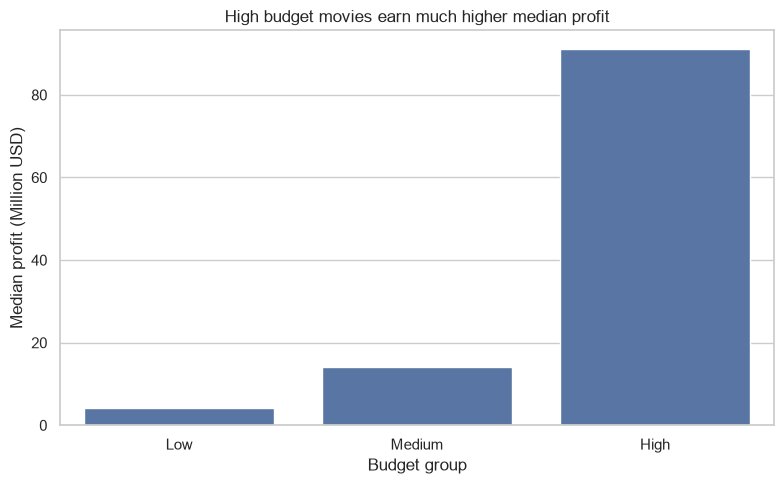

In [199]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

by_budget = (
    movies.groupby('Budget group', observed=True)['Profit']
    .median()
    .reset_index()
)
by_budget['Profit_M'] = by_budget['Profit'] / 1000000

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=by_budget, x='Budget group', y='Profit_M', ax=ax)

ax.set_title('High budget movies earn much higher median profit')
ax.set_xlabel('Budget group')
ax.set_ylabel('Median profit (Million USD)')

plt.tight_layout()
plt.show()

Movies in the 'High' budget group have a much higher median 'Profit' than 'Medium' and 'Low' budget movies.

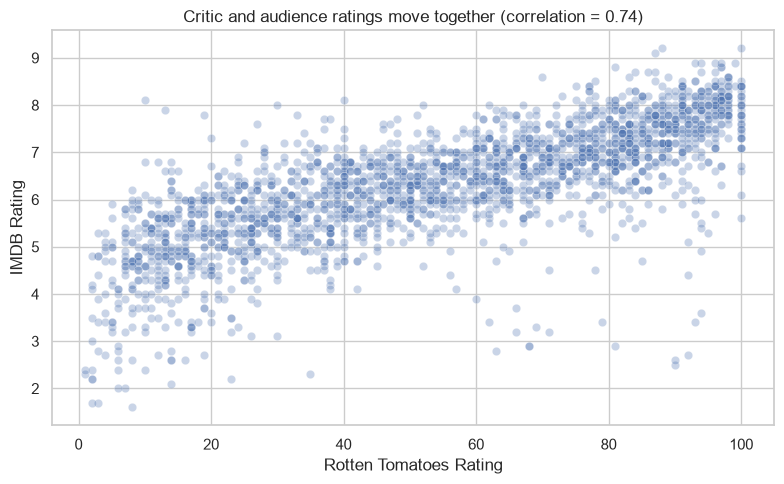

In [200]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=movies, x='Rotten Tomatoes Rating', y='IMDB Rating', alpha=0.3, ax=ax)

ax.set_title('Critic and audience ratings move together (correlation = 0.74)')
ax.set_xlabel('Rotten Tomatoes Rating')
ax.set_ylabel('IMDB Rating')

plt.tight_layout()
plt.show()

Upward pattern is showing that movies with higher 'Rotten Tomatoes Rating' scores also tend to get higher 'IMDB Rating' scores.

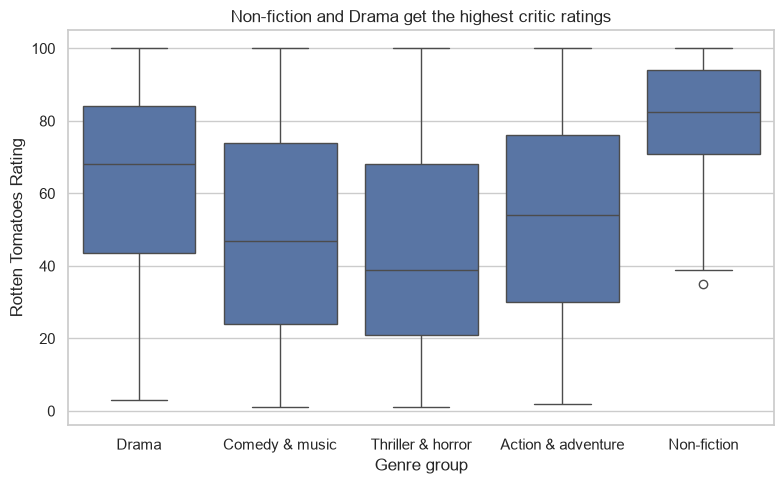

In [201]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=movies, x='Genre group', y='Rotten Tomatoes Rating', ax=ax)

ax.set_title('Non-fiction and Drama get the highest critic ratings')
ax.set_xlabel('Genre group')
ax.set_ylabel('Rotten Tomatoes Rating')

plt.tight_layout()
plt.show()

'Non-fiction' and 'Drama' have higher median 'Rotten Tomatoes Rating' scores than entertainment genres like 'Thriller & horror'

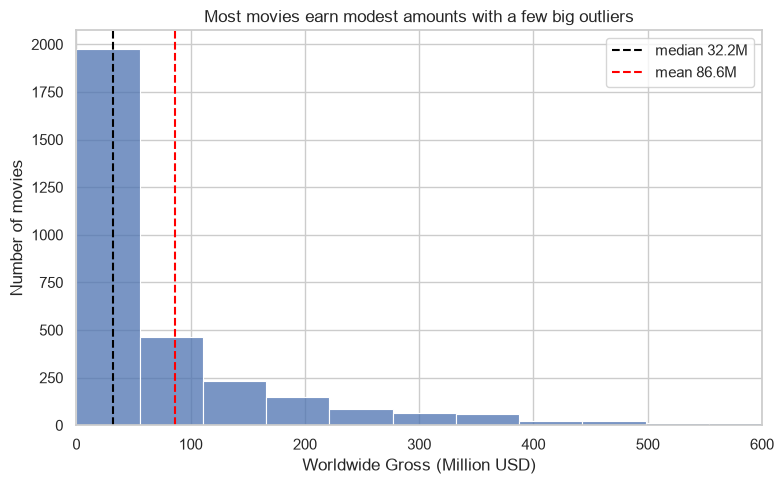

In [202]:
median_wg = movies['Worldwide Gross'].median() / 1000000
mean_wg = movies['Worldwide Gross'].mean() / 1000000

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=movies, x=movies['Worldwide Gross'] / 1000000, bins=50, ax=ax)

ax.axvline(median_wg, color='black', linestyle='--', label=f'median {median_wg:.1f}M')
ax.axvline(mean_wg, color='red', linestyle='--', label=f'mean {mean_wg:.1f}M')
ax.set_xlim(0, 600)

ax.set_title('Most movies earn modest amounts with a few big outliers')
ax.set_xlabel('Worldwide Gross (Million USD)')
ax.set_ylabel('Number of movies')
ax.legend()

plt.tight_layout()
plt.show()

The long right tail of extreme blockbusters pulls the mean ($86.6M) much higher than the median ($32.2M).

## 10. Check the data and the source

This dataset comes from the 'vega-datasets' repo on GitHub (https://github.com/vega/vega-datasets) and its docs page (https://vega.github.io/vega-datasets/) which collects public data for teaching and demos (as noted on the site, some flaws in the datasets are deliberate and existing files rarely change). The repo code is under the BSD-3-Clause license while each dataset keeps its original source license. From the source file (https://github.com/vega/vega-datasets/blob/main/data/movies.json) we can see the numbers were taken from public movie websites - 'The Numbers' for budgets and box office gross, and 'Rotten Tomatoes' and 'IMDb' for ratings. The table has 3201 movies from 1928 to 2020, so nothing after 2020 is included. Also it mostly covers bigger commercial films with US box office numbers.

Some columns cannot really be trusted because too much data is missing - 'US DVD Sales' has 82.4% missing, 'Running Time min' has 62.2%, and 'Director' has 41.6%. I would not claim that my 'Profit' column shows the real net profit of a movie studio because the data does not include marketing costs or the money taken by theaters or some other expenses (we do not know). We also do not know how these exact 3201 films were chosen or if older budgets and grosses were adjusted for inflation (judging by the small numbers for 1930s-1950s movies they probably were not)